## importing the necesary libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Loading the dataset

In [2]:
df = pd.read_csv(r"C:\Users\Administrator\sales_202610292013.csv")

In [5]:
## checking the dataset
df.head()

,customer_id,transaction_date,product_name,product_category,store_id,quantity,unit_price,total_amount,payment_method,promotion_active,is_holiday,inflation_index
0,C00085484,2025-04-07,Product_1459,Hair Care,S00000091,8,3.66,29.28,M-Pesa,No,Yes,2.62
1,C00027234,2024-03-05,Product_3904,Skin Care,S00000154,6,16.15,96.90,Credit Card,No,No,2.17
2,C00062273,2026-03-02,Product_462,Meat,S00000190,5,10.52,52.60,M-Pesa,No,No,2.27
3,C00021532,2024-09-02,Product_650,Baby Food,S00000029,3,23.13,69.39,M-Pesa,Yes,No,1.48
4,C00020196,2025-03-04,Product_1158,Bedding,S00000134,3,3.81,11.43,M-Pesa,No,No,2.43


In [6]:
# Converting date to datetime so we can plot trend over time
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

In [7]:
# checking the data info
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   customer_id       120000 non-null  object        
 1   transaction_date  120000 non-null  datetime64[ns]
 2   product_name      120000 non-null  object        
 3   product_category  120000 non-null  object        
 4   store_id          120000 non-null  object        
 5   quantity          120000 non-null  int64         
 6   unit_price        120000 non-null  float64       
 7   total_amount      120000 non-null  float64       
 8   payment_method    120000 non-null  object        
 9   promotion_active  120000 non-null  object        
 10  is_holiday        120000 non-null  object        
 11  inflation_index   120000 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(7)
memory usage: 11.0+ MB
None


Distribution of Payment Methods

C:\Users\Administrator\AppData\Local\Temp\ipykernel_15308\167770788.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x='payment_method',order=df['payment_method'].value_counts().index,palette='viridis')


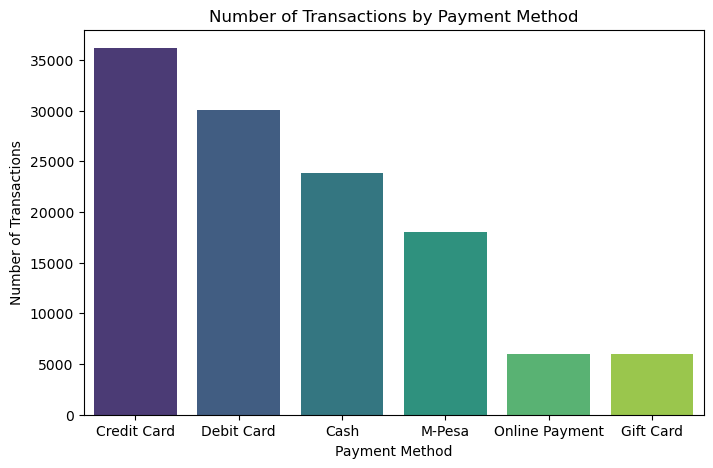

In [8]:
# finding which payment method is the most used
plt.figure(figsize=(8,5))
sns.countplot(data=df,x='payment_method',order=df['payment_method'].value_counts().index,palette='viridis')
plt.title('Number of Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.show()

Top 10 Product Categories by Revenue

C:\Users\Administrator\AppData\Local\Temp\ipykernel_15308\2035333146.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values,y=top_categories.index,palette='magma')


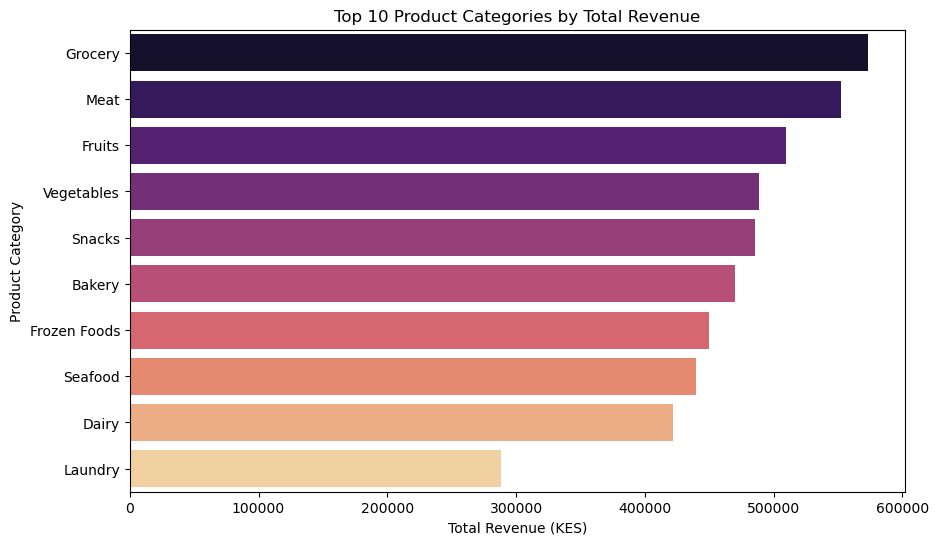

In [9]:
#Which product categories bring in the most money?
top_categories = df.groupby('product_category')['total_amount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_categories.values,y=top_categories.index,palette='magma')
plt.title('Top 10 Product Categories by Total Revenue')
plt.xlabel('Total Revenue (KES)')
plt.ylabel('Product Category')
plt.show()

Sales Trend Over Time

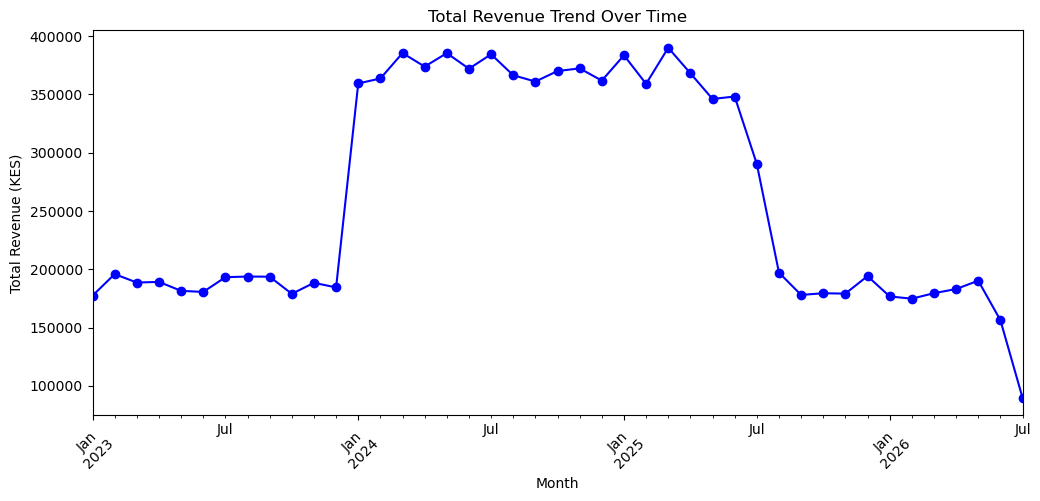

In [10]:
# How is our sales across diffrent months
# month and sum the revenue
monthly_sales = df.groupby(df['transaction_date'].dt.to_period('M'))['total_amount'].sum()

plt.figure(figsize=(12,5))
monthly_sales.plot(kind='line',marker='o',color='b')
plt.title('Total Revenue Trend Over Time')
plt.xlabel('Month')
plt.ylabel('Total Revenue (KES)')
plt.xticks(rotation=45)
plt.show()

Spendings between holidays vs non holidays days

C:\Users\Administrator\AppData\Local\Temp\ipykernel_15308\4188990022.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='is_holiday',y='total_amount',palette='Set2')


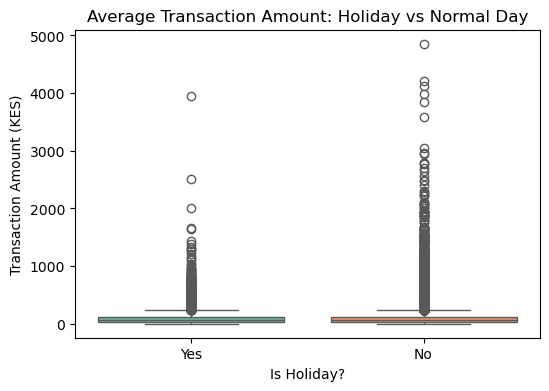

In [11]:
# Do people spend more on holidays?
plt.figure(figsize=(6,4))
sns.boxplot(data=df,x='is_holiday',y='total_amount',palette='Set2')
plt.title('Average Transaction Amount: Holiday vs Normal Day')
plt.xlabel('Is Holiday?')
plt.ylabel('Transaction Amount (KES)')
plt.show()

Analyzing transactions  disstributions

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df[df['total_amount'] < 500]['total_amount'], bins=30, kde=True, color='purple')
plt.title('Distribution of Transaction Amounts (Under 500 KES)')
plt.xlabel('Transaction Amount (KES)')
plt.ylabel('Frequency')
plt.show()